# 01 · Pose on one frame

**Goal:** find your body in a single photo from your practice video, and see exactly what MediaPipe gives back.

**The idea in plain English:** you hand MediaPipe one picture. It hands back 33 dots on your body (nose, shoulders, elbows, wrists, hips, knees, ankles...). Each dot has a position and a confidence score. Then we draw those dots and connect them into a stick figure.

**How this notebook works**
- Steps 0 to 4 are filled in. Run them with **Shift + Enter** and read the notes.
- Steps 5 to 7 are yours. Each has a hint. Try it before asking for help.

Check the top right corner says **Python (ai-tennis-coach)** before you start.

## Step 0 · Setup and video check

Load the tools, find the video, and print its basic facts. This is a light version of task 1.05 (metadata check): frame rate, size, and how many frames there are.

In [3]:
import urllib.request
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import pandas as pd
from mediapipe.tasks import python as mp_tasks
from mediapipe.tasks.python import vision

# The notebook lives in notebooks/, so the project folder is one level up
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# ---- Things you can change ----
CLIP_FOLDER = PROJECT / "data" / "raw"
CLIP_NAME = "IMG_1188"   # the tripod shot from behind
FRAME_NUMBER = 504       # which frame to analyse (try others later)
# -------------------------------

matches = sorted(CLIP_FOLDER.glob(CLIP_NAME + ".*"))
assert matches, f"No file named {CLIP_NAME} found in {CLIP_FOLDER}"
VIDEO_PATH = matches[0]

cap = cv2.VideoCapture(str(VIDEO_PATH))
assert cap.isOpened(), "OpenCV could not open the video"
fps = cap.get(cv2.CAP_PROP_FPS)
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("Video:     ", VIDEO_PATH.name)
print("Frame rate:", round(fps, 2), "frames per second")
print("Frames:    ", n_frames, f"(about {n_frames / fps:.1f} seconds)")
print("Size:      ", width, "x", height, "pixels")

Video:      IMG_1188.mov
Frame rate: 60.01 frames per second
Frames:     1713 (about 28.5 seconds)
Size:       2620 x 1194 pixels


## Step 1 · Grab one frame

A video is a flipbook. We jump to page `FRAME_NUMBER` and pull out that one photo.

**One gotcha worth remembering:** OpenCV stores colours as **B**lue-**G**reen-**R**ed (BGR). Almost everything else, including MediaPipe and matplotlib, expects **R**ed-**G**reen-**B**lue (RGB). So we flip the order right away. If you ever see a photo where your skin looks blue, this is why.

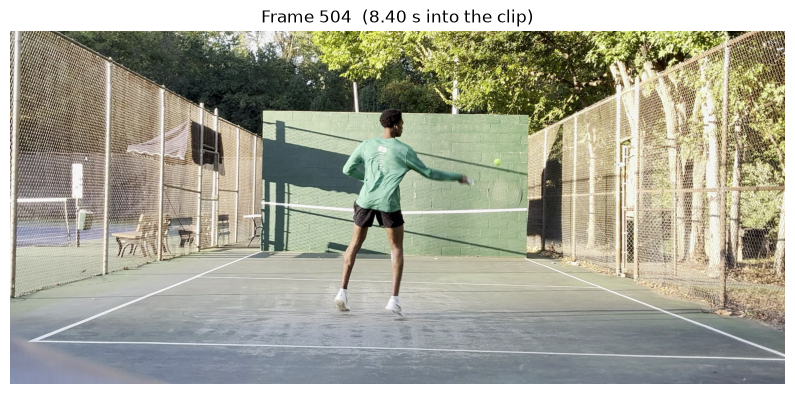

In [4]:
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_NUMBER)
ok, frame_bgr = cap.read()
assert ok, f"Could not read frame {FRAME_NUMBER}. Try a smaller number."

frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
h, w = frame_rgb.shape[:2]

plt.figure(figsize=(10, 6))
plt.imshow(frame_rgb)
plt.title(f"Frame {FRAME_NUMBER}  ({FRAME_NUMBER / fps:.2f} s into the clip)")
plt.axis("off")
plt.show()

## Step 2 · Get the model

MediaPipe's pose finder is a trained AI model stored in one file (`.task`). We download it once into `models/`. Git already ignores `.task` files, so it won't go to GitHub.

There are three sizes: **lite** (fastest, least accurate), **full** (middle), **heavy** (slowest, most accurate). We start with full. Swapping sizes later is a good experiment.

In [5]:
MODEL_VARIANT = "full"   # "lite", "full", or "heavy"

MODEL_DIR = PROJECT / "models"
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / f"pose_landmarker_{MODEL_VARIANT}.task"

if not MODEL_PATH.exists():
    url = (
        "https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
        f"pose_landmarker_{MODEL_VARIANT}/float16/latest/pose_landmarker_{MODEL_VARIANT}.task"
    )
    print("Downloading", url)
    urllib.request.urlretrieve(url, MODEL_PATH)

print("Model ready:", MODEL_PATH.name, f"({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

Model ready: pose_landmarker_full.task (9.4 MB)


## Step 3 · Run MediaPipe on the frame

Three moves: wrap our photo in MediaPipe's image format, build the pose finder ("landmarker"), and ask it to detect.

`IMAGE` mode means "treat this as a single photo with no past or future." Later, for full videos, we'll switch to `VIDEO` mode, which lets it use the previous frame to help find you in the next one.

In [6]:
mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)

options = vision.PoseLandmarkerOptions(
    base_options=mp_tasks.BaseOptions(model_asset_path=str(MODEL_PATH)),
    running_mode=vision.RunningMode.IMAGE,
    num_poses=1,
)

with vision.PoseLandmarker.create_from_options(options) as landmarker:
    result = landmarker.detect(mp_image)

if not result.pose_landmarks:
    print("No person found in this frame. Try a different FRAME_NUMBER.")
else:
    landmarks = result.pose_landmarks[0]   # the first (and only) person
    print("Found a person with", len(landmarks), "landmarks")

I0000 00:00:1792299228.184567 3436655 init-domain.cc:134] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792299228.252134 3436660 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792299228.278312 3436664 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792299228.314178 3436661 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


Found a person with 33 landmarks


## Step 4 · Look at the raw numbers

Before drawing anything, see what MediaPipe actually returned. Each row is one body point:

- **x, y:** where the point is, as a **fraction** of the picture. x = 0 is the left edge, 1 is the right edge. y = 0 is the **top**, 1 is the bottom (yes, upside down from school maths).
- **z:** a rough depth guess. Ignore it for now.
- **visibility:** how confident MediaPipe is that this point is visible, from 0 to 1.

Scroll the table. Which points have low visibility? Does that match what you can see in the photo?

In [7]:
NAMES = [p.name.lower() for p in vision.PoseLandmark]

table = pd.DataFrame({
    "name": NAMES,
    "x": [lm.x for lm in landmarks],
    "y": [lm.y for lm in landmarks],
    "z": [lm.z for lm in landmarks],
    "visibility": [lm.visibility for lm in landmarks],
}).round(3)

pd.set_option("display.max_rows", 40)
table

,name,x,y,z,visibility
0,nose,0.504,0.280,0.089,1.000
1,left_eye_inner,0.501,0.269,0.082,1.000
2,left_eye,0.499,0.268,0.082,1.000
3,left_eye_outer,0.497,0.267,0.082,1.000
4,right_eye_inner,0.504,0.270,0.074,1.000
5,right_eye,0.504,0.270,0.074,1.000
6,right_eye_outer,0.505,0.270,0.074,1.000
7,left_ear,0.491,0.268,0.062,1.000
8,right_ear,0.502,0.272,0.022,1.000
9,mouth_left,0.500,0.287,0.085,1.000


---
# Your turn

## Step 5 · Put the dots on the photo

Turn each landmark's fractions into **pixel** positions, then draw a dot there.

**Hints**
- You already have the picture's width `w` and height `h` (from Step 1).
- If x = 0.5 means "halfway across," what is that in pixels?
- `cv2.circle` only accepts whole numbers, so wrap your answers in `int(...)`.
- Draw on `annotated`, a copy, so the original photo stays clean.

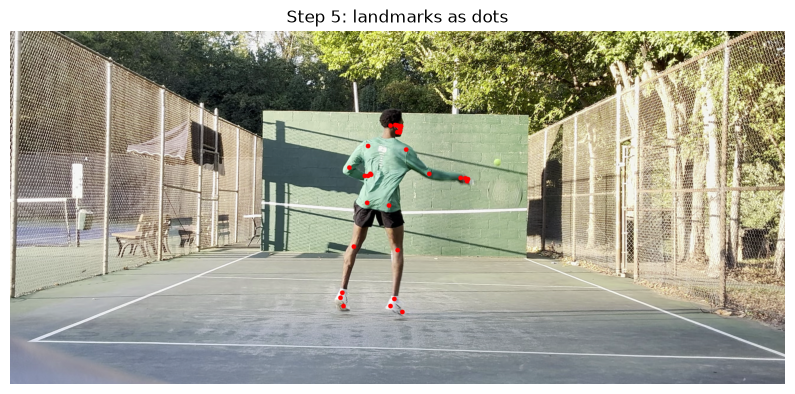

In [8]:
annotated = frame_rgb.copy()

for lm in landmarks:
    px = int(lm.x * w)  # YOUR CODE: pixel position across
    py = int(lm.y * h)  # YOUR CODE: pixel position down
    cv2.circle(annotated, (px, py), 8, (255, 0, 0), -1)   # red dot, filled

plt.figure(figsize=(10, 6))
plt.imshow(annotated)
plt.title("Step 5: landmarks as dots")
plt.axis("off")
plt.show()

## Step 6 · Connect the dots into a skeleton

MediaPipe gives you a list of which points connect to which (shoulder to elbow, elbow to wrist, and so on). Each connection has a `.start` and `.end`, which are **positions in the `landmarks` list**.

**Hints**
- `CONNECTIONS[0].start` and `CONNECTIONS[0].end` give you two numbers. Use them to pick two landmarks out of `landmarks`.
- Convert both to pixels the same way you did in Step 5. Copying your Step 5 maths is fine.
- `cv2.line(image, (x1, y1), (x2, y2), colour, thickness)` draws a line.
- Draw lines first, then the dots on top, so the dots don't get covered.

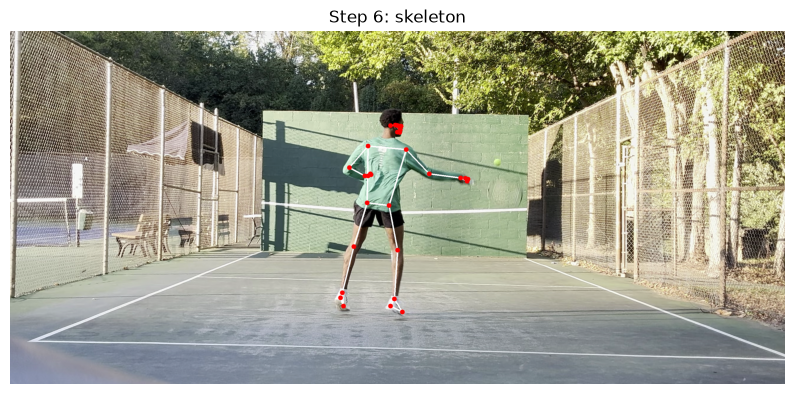

In [11]:
CONNECTIONS = vision.PoseLandmarksConnections.POSE_LANDMARKS
skeleton = frame_rgb.copy()

# Draw the lines (the "connect the dots" part)
for c in CONNECTIONS:
    a = landmarks[c.start]          # first dot in this pair
    b = landmarks[c.end]            # second dot in this pair

    ax = int(a.x * w)               # first dot, pixels across
    ay = int(a.y * h)               # first dot, pixels down
    bx = int(b.x * w)               # second dot, pixels across
    by = int(b.y * h)               # second dot, pixels down

    cv2.line(skeleton, (ax, ay), (bx, by), (255, 255, 255), 3)   # white line

# Draw the dots on top, same as Step 5
for lm in landmarks:
    px = int(lm.x * w)
    py = int(lm.y * h)
    cv2.circle(skeleton, (px, py), 8, (255, 0, 0), -1)            # red dot

plt.figure(figsize=(10, 6))
plt.imshow(skeleton)
plt.title("Step 6: skeleton")
plt.axis("off")
plt.show()


## Step 7 · Show which points MediaPipe is unsure about

Not every dot deserves the same trust. Colour each dot by its `visibility`: green if it's at or above the threshold, red if it's below.

**Hints**
- `lm.visibility` is a number from 0 to 1.
- An `if / else` inside your loop picks the colour. In RGB, green is `(0, 255, 0)` and red is `(255, 0, 0)`.
- Change `VIS_THRESHOLD` and rerun. How many points flip colour?

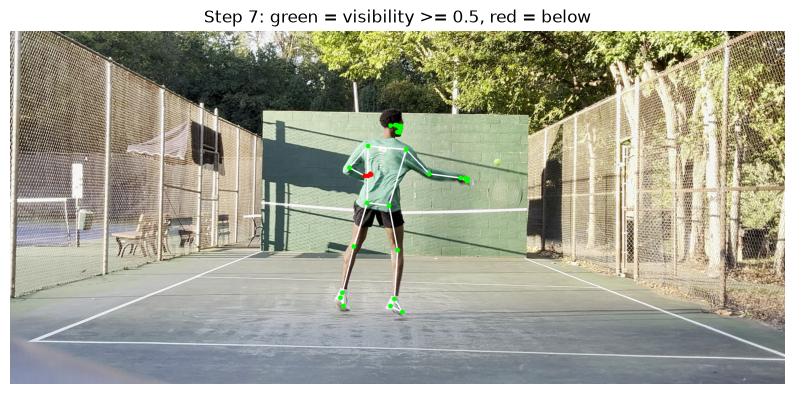

In [12]:
VIS_THRESHOLD = 0.5
confidence_view = frame_rgb.copy()

# Lines first, in white (same as Step 6)
for c in CONNECTIONS:
    a = landmarks[c.start]
    b = landmarks[c.end]
    cv2.line(confidence_view,
             (int(a.x * w), int(a.y * h)),
             (int(b.x * w), int(b.y * h)),
             (255, 255, 255), 3)

# Dots on top: green if MediaPipe is confident, red if it's guessing
for lm in landmarks:
    px = int(lm.x * w)
    py = int(lm.y * h)
    if lm.visibility >= VIS_THRESHOLD:
        colour = (0, 255, 0)      # green = confident
    else:
        colour = (255, 0, 0)      # red = unsure
    cv2.circle(confidence_view, (px, py), 8, colour, -1)

plt.figure(figsize=(10, 6))
plt.imshow(confidence_view)
plt.title(f"Step 7: green = visibility >= {VIS_THRESHOLD}, red = below")
plt.axis("off")
plt.show()

## Wrap-up questions (answer in this cell, just text)

1. Which body points were red in Step 7? Why do you think MediaPipe was unsure about those ones in particular?
2. Pick a frame in the middle of a swing (change `FRAME_NUMBER` in Step 0 and rerun everything). Does the skeleton still line up with your racket arm?
3. This camera was behind you. What do you think a side-on camera would see better? What would it see worse?

*Your answers:*


In [ ]:
# Optional: save your Step 7 picture to outputs/
out_dir = PROJECT / "outputs"
out_dir.mkdir(exist_ok=True)
out_path = out_dir / f"pose_{CLIP_NAME}_frame{FRAME_NUMBER}.png"
cv2.imwrite(str(out_path), cv2.cvtColor(confidence_view, cv2.COLOR_RGB2BGR))
print("Saved", out_path)